# Chapter 3: Behavioural Modelling and Decision Processes

**Aventum Round 1 prep · STRATEGY.md §5.2** · Time needed: about 90 minutes

### Syllabus
| No. | Topic | Interview use |
|---|---|---|
| 3.1 | Behavioural cloning (BC): learning an underwriter's policy from logged decisions | "What is behavioural cloning?", "an underwriter Digital Twin" |
| 3.2 | Covariate shift, compounding errors, and DAgger | "When does BC fail?" |
| 3.3 | Selective labels and bias | "Why is learning from historical decisions dangerous in insurance?" |
| 3.4 | Markov Decision Processes and value iteration | "What does 'RL-inspired' mean in the JD?" |
| 3.5 | Contextual bandits: ε-greedy, Thompson sampling, logging propensities | "How would you learn which recommendation works?" |
| 3.6 | Inverse RL, GAIL, offline RL (concept level) | "How is IRL different from BC?" |

**Key vocabulary** (Board-style "Definitions" box)
- **State $s$**: everything the decision-maker sees (submission fields, broker, history).
- **Action $a$**: what they do (quote / refer / decline, a price loading, a nudge).
- **Policy $\pi(a \mid s)$**: the rule mapping states to (probabilities of) actions. *A Digital Twin of an underwriter is a learned policy.*
- **Reward $r$**: a number saying how good an outcome was (profit, bind, low loss).

## 0. Setup

In [1]:
import numpy as np                  # linear algebra
import pandas as pd                 # data processing
import matplotlib.pyplot as plt     # plots
from sklearn.linear_model import LogisticRegression, LinearRegression
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import accuracy_score, confusion_matrix

np.random.seed(42)
print("Ready")

Ready


---
## 3.1 Behavioural Cloning

### Theory
**Behavioural cloning = supervised learning on (state, action) pairs logged from an expert.** You don't need rewards or a simulator, just the history of what the expert did. For Aventum: "given this submission, what would our senior underwriter do?"

### Formula
Model the policy as a classifier $\pi_\theta(a \mid s)$ and maximise the log-likelihood of the expert's actions:
$$\boxed{\theta^* = \arg\max_\theta \sum_{i=1}^{n} \log \pi_\theta(a_i \mid s_i)}$$
That is exactly what logistic regression or a neural net with cross-entropy loss already does. **BC is not a new algorithm; it's a new framing of classification.**

For 3 actions a common choice is the **softmax policy**: each action gets a score $z_a(s)$, and
$$\pi(a \mid s) = \frac{e^{z_a}}{\sum_{b} e^{z_b}}$$

### Solved Example 3.1 (softmax policy by hand)
**Q.** For a submission, the learned scores are Quote = 2, Refer = 1, Decline = 0. Find the policy probabilities.

**Solution.** $e^2 = 7.389,\ e^1 = 2.718,\ e^0 = 1$. Sum = 11.107.
- π(Quote) = 7.389 / 11.107 = **0.665**
- π(Refer) = 2.718 / 11.107 = **0.245**
- π(Decline) = 1 / 11.107 = **0.090**

**Ans.** The twin would quote this risk about 2 times in 3.

In [2]:
z = np.array([2.0, 1.0, 0.0])
print(dict(zip(["Quote", "Refer", "Decline"], (np.exp(z) / np.exp(z).sum()).round(3))))

{'Quote': np.float64(0.665), 'Refer': np.float64(0.245), 'Decline': np.float64(0.09)}


#### Program 3.1: simulate an underwriter's decision log
The "true" underwriter (which we pretend not to know) decides with a softmax over scores built from the risk features.

In [3]:
rng = np.random.default_rng(0)
n = 5000
sub = pd.DataFrame({
    "log_premium":   rng.normal(11, 1, n),
    "prior_claims":  rng.poisson(1.0, n),
    "lob":           rng.choice(["Property", "Marine", "Cyber"], n, p=[0.5, 0.3, 0.2]),
    "broker_tier":   rng.choice(["A", "B", "C"], n, p=[0.3, 0.4, 0.3]),
})
lob_risk  = sub["lob"].map({"Property": 0.0, "Marine": 0.3, "Cyber": 0.8})
tier_pref = sub["broker_tier"].map({"A": 0.6, "B": 0.2, "C": -0.4})

# true (hidden) underwriter scores
z_quote   = 1.5 - 0.8 * sub["prior_claims"] - lob_risk + tier_pref
z_refer   = 0.2 + 0.9 * (sub["log_premium"] - 11)          # big risks get referred
z_decline = -0.5 + 0.6 * sub["prior_claims"] + lob_risk
Z = np.c_[z_quote, z_refer, z_decline]
P_true = np.exp(Z) / np.exp(Z).sum(axis=1, keepdims=True)
actions = np.array(["Quote", "Refer", "Decline"])
sub["action"] = [actions[rng.choice(3, p=p)] for p in P_true]

sub.head()

,log_premium,prior_claims,lob,broker_tier,action
0,11.125730,0,Property,B,Quote
1,10.867895,1,Marine,C,Decline
2,11.640423,1,Property,B,Quote
3,11.104900,1,Property,A,Refer
4,10.464331,1,Property,A,Decline


In [4]:
sub["action"].value_counts(normalize=True).round(3)

action
Quote      0.412
Decline    0.320
Refer      0.268
Name: proportion, dtype: float64

#### Program 3.2: clone the underwriter with two models

In [5]:
X = pd.get_dummies(sub.drop(columns="action"), drop_first=True, dtype=int)
y = sub["action"]
Xtr, Xte, ytr, yte = X.iloc[:4000], X.iloc[4000:], y.iloc[:4000], y.iloc[4000:]

bc_lr  = LogisticRegression(max_iter=2000).fit(Xtr, ytr)
bc_gbm = GradientBoostingClassifier(random_state=0).fit(Xtr, ytr)

# the best any model can do: predict the true policy's most likely action
bayes = actions[P_true[4000:].argmax(axis=1)]
print("Accuracy, multinomial LR :", round(accuracy_score(yte, bc_lr.predict(Xte)), 3))
print("Accuracy, GBM            :", round(accuracy_score(yte, bc_gbm.predict(Xte)), 3))
print("Accuracy, TRUE policy    :", round(accuracy_score(yte, bayes), 3), " <- ceiling: the underwriter is not deterministic")
pd.DataFrame(confusion_matrix(yte, bc_lr.predict(Xte), labels=actions),
             index=[f"true {a}" for a in actions], columns=[f"pred {a}" for a in actions])

Accuracy, multinomial LR : 0.586
Accuracy, GBM            : 0.573
Accuracy, TRUE policy    : 0.59  <- ceiling: the underwriter is not deterministic


,pred Quote,pred Refer,pred Decline
true Quote,299,63,57
true Refer,106,104,68
true Decline,86,34,183


#### Explanation
- Even the **true** policy only scores about 60%, because human decisions are noisy. A clone can't be "100% accurate", and **agreement with the human is capped by the human's own consistency.** (In practice, measure two underwriters' agreement on the same risks: that's your ceiling.)
- LR is close to the ceiling because the true scores are linear. GBM gives no extra lift here.

> **Note (insurance framing):** this is your **underwriter Digital Twin**. Uses: queue triage, consistency checks ("this decision is unusual for this underwriter"), training juniors, and as the *policy* inside a simulator (Notebook 07).

---
## 3.2 Covariate Shift, Compounding Errors and DAgger

### Theory
BC trains on states **the expert** visited. When the **clone** acts, it makes small mistakes, which lead to states the expert never visited, where it has no training data, so it makes bigger mistakes. **The errors compound.**

- Supervised learning assumes train and test states come from the same distribution. BC breaks that assumption as soon as the clone's own actions change which states it sees. This is **covariate shift**.
- Theory: with per-step error $\epsilon$ over a horizon $T$, BC's total cost can grow like $O(\epsilon T^2)$, not $O(\epsilon T)$.

### DAgger (Dataset Aggregation), the fix
1. Train $\pi_1$ by BC on expert data $D$.
2. **Run the clone** $\pi_i$ and record the states *it* visits.
3. **Ask the expert to label** those states with what they would have done.
4. Add them to $D$ and retrain. Repeat.

*Insurance analogy:* the twin recommends slightly different terms, brokers respond by sending a different risk mix, and now the twin faces submissions unlike anything in its history. DAgger = have underwriters review the twin's recommendations on the *new* mix and feed those labels back. (That's also why a human-in-the-loop review step is valuable data, not just a safety check.)

#### Program 3.3: compounding errors on a toy control problem
A deliberately unstable system: $x_{t+1} = 1.5\,x_t + a_t + \varepsilon$ (left alone, any wobble grows by 50% a step). The expert keeps $x$ near 0 with $a^* = -1.5x$.

Two realistic details create the failure:
- The expert is **precise**: in the demonstrations, noise is small (σ = 0.03), so the expert **never visits wobbly states** and never shows how to recover from them.
- The clone is a decision tree. It is accurate inside the range it was trained on, but **outside that range it just repeats the edge value**. It can't extrapolate.

When the clone is deployed in a noisier world (σ = 0.15), it soon lands outside the expert's range.

In [6]:
G = 1.5
expert = lambda x: -G * x

def rollout(policy, T=40, seed=None, noise=0.15):
    r = np.random.default_rng(seed)
    x, xs = r.normal(0, noise), []
    for _ in range(T):
        xs.append(x)
        x = G * x + policy(x) + r.normal(0, noise)
        if abs(x) > 50: break                       # crashed
    return np.array(xs)

# expert demonstrations: a precise expert, so low noise
S = np.concatenate([rollout(expert, seed=s, noise=0.03) for s in range(30)])
A = expert(S)
print(f"expert visited x in [{S.min():.2f}, {S.max():.2f}]")

def fit_clone(S, A):
    tree = DecisionTreeRegressor(max_depth=6).fit(S.reshape(-1, 1), A)
    return lambda x: tree.predict([[x]])[0]

def crash_rate(policy, n=60):
    return np.mean([abs(rollout(policy, seed=1000 + s)[-1]) > 2 for s in range(n)])

bc = fit_clone(S, A)
print("Crash rate, expert:", crash_rate(expert))
print("Crash rate, BC    :", crash_rate(bc))

expert visited x in [-0.09, 0.10]
Crash rate, expert: 0.0


Crash rate, BC    : 0.8666666666666667


In [7]:
# DAgger: run the clone, let the expert label the states the CLONE visited, aggregate, retrain
S_agg, A_agg, policy = S.copy(), A.copy(), bc
dagger_curve = [crash_rate(bc)]
for it in range(5):
    visited = np.concatenate([rollout(policy, seed=500 + 10 * it + s) for s in range(10)])
    S_agg = np.r_[S_agg, visited]
    A_agg = np.r_[A_agg, expert(visited)]         # expert labels the clone's states
    policy = fit_clone(S_agg, A_agg)
    dagger_curve.append(crash_rate(policy))
    print(f"DAgger iteration {it + 1}: states seen in [{S_agg.min():.2f}, {S_agg.max():.2f}], crash rate {dagger_curve[-1]:.2f}")

DAgger iteration 1: states seen in [-47.98, 43.73], crash rate 0.03


DAgger iteration 2: states seen in [-47.98, 43.73], crash rate 0.00


DAgger iteration 3: states seen in [-47.98, 43.73], crash rate 0.00


DAgger iteration 4: states seen in [-47.98, 43.73], crash rate 0.00


DAgger iteration 5: states seen in [-47.98, 43.73], crash rate 0.00


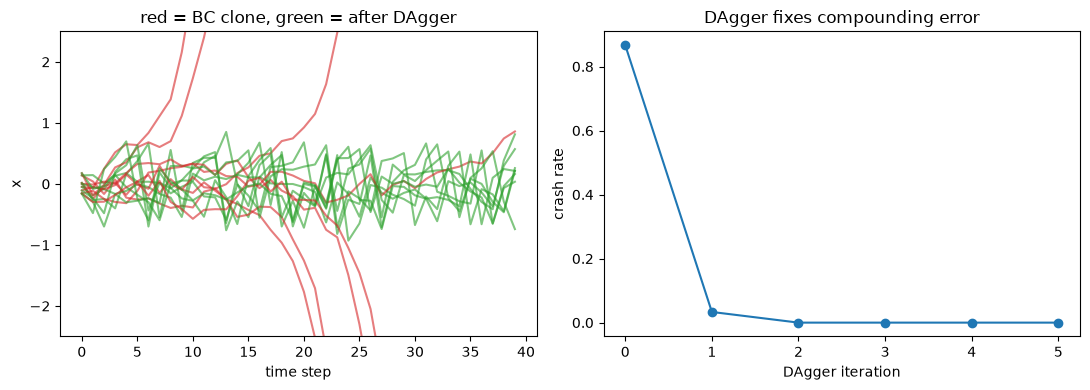

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for s in range(8):
    ax[0].plot(rollout(bc, seed=1000 + s), color="tab:red", alpha=0.6)
    ax[0].plot(rollout(policy, seed=1000 + s), color="tab:green", alpha=0.6)
ax[0].set_ylim(-2.5, 2.5); ax[0].set_title("red = BC clone, green = after DAgger"); ax[0].set_xlabel("time step"); ax[0].set_ylabel("x")
ax[1].plot(dagger_curve, "o-"); ax[1].set_xlabel("DAgger iteration"); ax[1].set_ylabel("crash rate"); ax[1].set_title("DAgger fixes compounding error")
plt.tight_layout(); plt.show()

#### Explanation
- The BC clone is accurate **on the states the expert visited** (a narrow band around 0). One unlucky step takes it outside that band. There the tree repeats its edge value, which under-corrects, so the unstable dynamics amplify the error until it crashes. Small error → unfamiliar state → bigger error: **compounding**.
- Note what DAgger does *not* fix: if the model were too simple to represent the expert even on familiar states (say a depth-1 tree), more data wouldn't help. DAgger fixes **coverage**, not **capacity**.
- DAgger adds exactly the states where the clone goes wrong, labelled by the expert, so the coverage widens and the crash rate drops. (The "states seen" range jumps to about ±48 after iteration 1 because the clone's crashed runs are added too. Those runaway states, with the expert's corrections, are exactly the data BC never had.)
- **This is the textbook failure of behavioural cloning.** Say "covariate shift" and "DAgger" in the interview.

---
## 3.3 Selective Labels (an insurance-specific trap)

### Theory
We only observe **losses on risks that were bound**. Declined risks never get a loss outcome. So a "loss model" trained on historical data learns only from risks the past underwriters *liked*. If the underwriters used information **not in the data** (a phone call, a gut feel about the insured), the model underestimates the risk on submissions they would have declined.

In [9]:
rng = np.random.default_rng(1)
n = 20000
x = rng.normal(0, 1, n)                 # recorded risk feature
u = rng.normal(0, 1, n)                 # what the underwriter knew but the data doesn't record
p_loss = 1 / (1 + np.exp(-(-2 + 0.8 * x + 1.2 * u)))
loss = rng.random(n) < p_loss
bound = (0.8 * x + 1.2 * u + rng.normal(0, 0.5, n)) < 0.3    # underwriters bind the risks that look safe to them

m = LogisticRegression().fit(x[bound].reshape(-1, 1), loss[bound])     # trained on bound risks only
pred_declined = m.predict_proba(x[~bound].reshape(-1, 1))[:, 1].mean()
print(f"share bound: {bound.mean():.2f}")
print(f"TRUE loss rate on declined risks     : {loss[~bound].mean():.3f}")
print(f"MODEL's predicted rate on them       : {pred_declined:.3f}   <- badly underestimated")

share bound: 0.58
TRUE loss rate on declined risks     : 0.345
MODEL's predicted rate on them       : 0.098   <- badly underestimated


#### Explanation
The model never saw a loss on a declined risk, and it can't see `u`, so it thinks the declined risks are only slightly worse. If you used it to **auto-accept** risks the humans used to decline, losses would surprise you.

**Mitigations to mention:** a small randomised exploration budget (a few marginal risks bound under controlled terms), bounds and sensitivity analysis, reject inference, and human review of any shift in acceptance policy.

**Bias:** cloning reproduces past decisions *including their biases*. Under **FCA Consumer Duty** (good outcomes for retail customers) and fair-value rules, a twin that encodes historic unfairness is a conduct risk. Run fairness checks on outputs by protected or proxy groups.

---
## 3.4 Markov Decision Processes (MDP)

### Theory
An MDP is the maths of **sequential** decisions: $(S, A, P, R, \gamma)$
- $S$ states, $A$ actions, $P(s' \mid s, a)$ transitions, $R$ rewards, $\gamma \in [0,1)$ discount (a reward later is worth less than one now).

**Goal:** a policy that maximises expected discounted reward. Its value satisfies the **Bellman optimality equation**:
$$\boxed{V^*(s) = \max_a \Big[ R(s,a) + \gamma \sum_{s'} P(s' \mid s,a)\, V^*(s') \Big]}$$

**Value iteration:** start with $V_0 = 0$ and apply the right-hand side repeatedly. It converges because each application shrinks errors by a factor $\gamma$.

### Solved Example 3.2 (chase the broker or wait?)
A quote is out with a broker (state Q). Each week:

| Action | Cost | P(bind) | P(lost) | P(still deciding) |
|---|---|---|---|---|
| Wait | 0 | 0.2 | 0.1 | 0.7 |
| Chase | −1 | 0.4 | 0.1 | 0.5 |

Binding pays +10, and Bound and Lost are terminal (value 0 afterwards). Take $\gamma = 0.9$.

**Q.** Do two steps of value iteration, then find the exact $V^*(Q)$ and the optimal action.

**Solution.**
- $Q_{\text{wait}}(V) = 0.2(10) + 0.9(0.7)V = 2 + 0.63V$
- $Q_{\text{chase}}(V) = -1 + 0.4(10) + 0.9(0.5)V = 3 + 0.45V$

Iteration 1 ($V_0 = 0$): wait = 2, chase = 3, so $V_1 = 3$.
Iteration 2: wait = 2 + 0.63(3) = 3.89, chase = 3 + 0.45(3) = 4.35, so $V_2 = 4.35$.

Exact: suppose chase is optimal. Then $V = 3 + 0.45V \Rightarrow V = 3 / 0.55 = 5.4545$.
Check wait at that V: 2 + 0.63(5.4545) = 5.436 < 5.4545 ✓

**Ans.** $V^*(Q) \approx 5.45$, and the optimal action is **Chase**, but only just. A small change in the chase cost flips the decision (see Exercise 3).

In [10]:
def value_iteration(chase_cost=1.0, gamma=0.9, iters=60):
    V, trace = 0.0, []
    for _ in range(iters):
        q_wait  = 0.2 * 10 + gamma * 0.7 * V
        q_chase = -chase_cost + 0.4 * 10 + gamma * 0.5 * V
        V = max(q_wait, q_chase)
        trace.append((q_wait, q_chase, V))
    best = "Chase" if q_chase > q_wait else "Wait"
    return pd.DataFrame(trace, columns=["Q_wait", "Q_chase", "V"]), best

trace, best = value_iteration()
print(trace.head(3).round(4)); print("...")
print(trace.tail(1).round(4)); print("optimal action:", best)

   Q_wait  Q_chase       V
0  2.0000   3.0000  3.0000
1  3.8900   4.3500  4.3500
2  4.7405   4.9575  4.9575
...
    Q_wait  Q_chase       V
59  5.4364   5.4545  5.4545
optimal action: Chase


> **Note:** this assumes we **know** $P$ and $R$. Reinforcement learning is what you do when you don't, and must learn from experience. **Offline RL** learns from logged data only (no live exploration), which suits regulated decisions. Its main danger is valuing actions the logs rarely contain, so methods like **Conservative Q-Learning** penalise those.

---
## 3.5 Contextual Bandits

### Theory
A **contextual bandit** is a one-step MDP: see a context $x$, choose an action, receive a reward, done. Examples: which follow-up template to send a broker, which submissions to show first, which pricing recommendation to surface.

The core tension is **exploration vs exploitation**: use what looks best now, or try others to learn?

| Algorithm | Rule |
|---|---|
| **ε-greedy** | With probability $1-\varepsilon$ pick the best-looking arm, else a random one |
| **Thompson sampling** | Keep a posterior per arm (e.g. Beta for a success rate). Sample a plausible rate from each and pick the highest sample |
| **LinUCB** | Pick the arm with the highest *estimate + uncertainty bonus*, with a linear model in the context |

**Log the propensity!** Record $\pi(a \mid x)$, the probability with which you chose the action you took. Without it you can't evaluate a *new* policy on old logs later (off-policy evaluation, Notebook 06).

### Solved Example 3.3 (ε-greedy propensities)
**Q.** 3 arms, ε = 0.1, and arm 2 currently looks best. What is the probability of choosing each arm?

**Solution.** The random branch picks each arm with probability 0.1 / 3 = 0.0333.
- P(arm 2) = 0.9 + 0.0333 = **0.9333**
- P(arm 1) = P(arm 3) = **0.0333**

**Ans.** These numbers go in the `propensity` column of the log.

### Solved Example 3.4 (Thompson sampling posterior)
**Q.** An arm has 7 successes in 10 trials. With a Beta(1,1) prior, what is the posterior and its mean?

**Solution.** Beta(1 + 7, 1 + 3) = **Beta(8, 4)**, mean = 8 / 12 = **0.667**. Thompson sampling draws one random number from Beta(8, 4) and compares it with the other arms' draws. Arms with few trials have wide posteriors, so they sometimes win the draw, and that's the exploration.

#### Program 3.4: ε-greedy vs Thompson sampling, with a propensity log

In [11]:
contexts = ["Property", "Marine", "Cyber"]
arms = ["call broker", "email reminder", "revised terms"]
true_rate = np.array([[0.10, 0.15, 0.08],     # Property: email works best
                      [0.20, 0.10, 0.12],     # Marine: call works best
                      [0.05, 0.06, 0.18]])    # Cyber: revised terms work best

def run_bandit(algo, T=6000, eps=0.1, seed=0):
    r = np.random.default_rng(seed)
    succ = np.zeros((3, 3)); fail = np.zeros((3, 3))
    log, regret = [], 0.0
    for t in range(T):
        c = r.integers(3)
        if algo == "eps":
            rates = succ[c] / np.maximum(succ[c] + fail[c], 1)
            best = rates.argmax()
            probs = np.full(3, eps / 3); probs[best] += 1 - eps
        else:  # Thompson: estimate P(arm wins the draw) by Monte Carlo, for the log
            draws = r.beta(1 + succ[c], 1 + fail[c], size=(200, 3))
            probs = np.bincount(draws.argmax(axis=1), minlength=3) / 200
            probs = np.clip(probs, 1e-3, None); probs /= probs.sum()
        a = r.choice(3, p=probs)
        reward = r.random() < true_rate[c, a]
        succ[c, a] += reward; fail[c, a] += 1 - reward
        regret += true_rate[c].max() - true_rate[c, a]
        log.append(dict(t=t, context=contexts[c], action=arms[a], propensity=probs[a], reward=int(reward), cum_regret=regret))
    return pd.DataFrame(log)

log_eps = run_bandit("eps")
log_ts  = run_bandit("ts")
log_ts.head()

,t,context,action,propensity,reward,cum_regret
0,0,Cyber,email reminder,0.335,0,0.12
1,1,Marine,call broker,0.285,1,0.12
2,2,Property,revised terms,0.335,0,0.19
3,3,Property,email reminder,0.440,0,0.19
4,4,Property,call broker,0.595,0,0.24


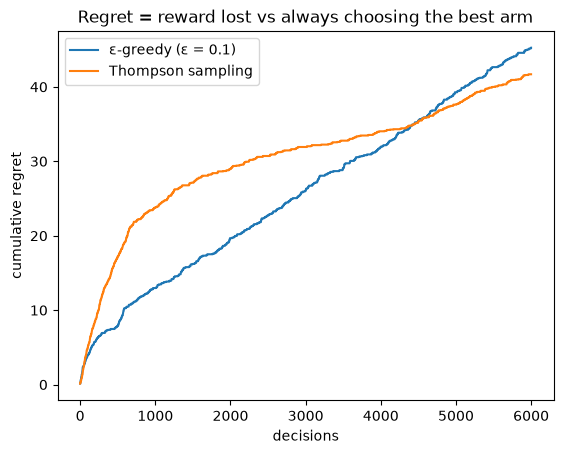

Final regret: ε-greedy 45.3 | Thompson 41.7


In [12]:
plt.plot(log_eps["cum_regret"], label="ε-greedy (ε = 0.1)")
plt.plot(log_ts["cum_regret"], label="Thompson sampling")
plt.xlabel("decisions"); plt.ylabel("cumulative regret"); plt.legend()
plt.title("Regret = reward lost vs always choosing the best arm"); plt.show()
print("Final regret: ε-greedy", round(log_eps.cum_regret.iloc[-1], 1), "| Thompson", round(log_ts.cum_regret.iloc[-1], 1))

#### Explanation
- **Regret** = the reward you'd have got from the best arm, minus what you actually got. Lower is better.
- ε-greedy keeps exploring at a fixed 10% forever, so its regret grows linearly. Thompson explores less as it becomes confident, so its regret flattens.
- The `propensity` column is what makes this log reusable. Notebook 06 uses it to evaluate a new policy **without deploying it**.

---
## 3.6 Beyond BC: IRL, GAIL, offline RL (concept level)

| Method | Learns | Needs | Strength | Weakness |
|---|---|---|---|---|
| **Behavioural cloning** | π(a∣s) directly | (s, a) logs | Simple, it's just supervised learning | Compounding error, copies bias |
| **DAgger** | π(a∣s) | An expert available to label new states | Fixes covariate shift | Expert time |
| **Inverse RL** | The **reward** the expert optimises | (s, a) logs + a dynamics model | Transfers when the environment changes; explains *why* | Ill-posed, expensive |
| **GAIL** | A policy whose behaviour a discriminator can't tell apart from the expert's | Simulator / rollouts | Strong imitation | GAN-style instability |
| **Offline RL** (CQL, IQL) | A policy that **improves on** the logs | Logged (s, a, r, s′) | Can beat the historical policy | Overvalues actions the logs rarely contain |
| **Contextual bandit** | Best one-step action per context | Logged propensities | Simple, safe, measurable | One-step only |

**"RL-inspired methods" in the JD** most likely means bandits and offline RL for decisioning (pricing nudges, triage, broker engagement), plus simulation via the Digital Twin. It doesn't mean game-playing RL.

---
## Exercise 3.1
1. Scores are Quote = 0, Refer = 0, Decline = 0. What is the policy? What does it mean for a twin to output this?
2. In Solved Example 3.2, change the chase cost to 2. Which action is optimal now, and what is $V^*(Q)$? (Verify with `value_iteration(chase_cost=2)`.)
3. With ε = 0.2 and 4 arms, what is the propensity of the greedy arm?
4. Why can't you evaluate a new bandit policy on old logs that lack propensities?
5. An underwriter twin agrees with underwriters 92% of the time in shadow mode. Name two reasons that number could be misleading.

<details><summary><b>Answers</b></summary>

1. Uniform: 1/3 each. The model has no information for this submission, so flag it for a human.
2. Chase: $1 + 0.45V \Rightarrow V = 1/0.55 = 1.82$. Wait: $2 + 0.63V \Rightarrow V = 2/0.37 = 5.41$. Check: at V = 5.41, chase gives 1 + 0.45(5.41) = 3.43 < 5.41, so **Wait** is optimal and $V^* = 5.41$.
3. 0.8 + 0.2/4 = **0.85**.
4. Off-policy estimators reweight each logged reward by $\pi_{\text{new}}(a \mid x) / \pi_{\text{old}}(a \mid x)$. Without $\pi_{\text{old}}$ you can't correct for the old policy having chosen some actions more often.
5. (a) Most submissions are easy and everyone agrees on them, so check agreement on the **hard or borderline** cases. (b) Agreement isn't outcome quality: the twin may copy the humans' mistakes or biases. (c) Underwriters who can see the twin's output may anchor on it.
</details>

## Viva / Interview Questions (STRATEGY §9)
**Q. What is behavioural cloning and when does it fail?**
Supervised learning of a policy from logged expert (state, action) pairs: it's how you'd build an underwriter twin. It fails under covariate shift: once the clone's own actions take it into states the expert never visited, errors compound. DAgger fixes this by having experts label the clone's states. In insurance there are two more traps: selective labels (we only see losses on bound risks) and reproducing historic bias, which is a Consumer Duty issue.

**Q. Where would you use RL at an insurer?**
Mostly contextual bandits and offline RL rather than full online RL: we can't explore freely on live risks. Start with a bandit for low-stakes choices like broker follow-ups, log the propensities from day one, and evaluate new policies off-policy before any A/B test.

## Formula Sheet
| Concept | Formula |
|---|---|
| BC objective | $\max_\theta \sum \log \pi_\theta(a_i \mid s_i)$ |
| Softmax policy | $\pi(a \mid s) = e^{z_a} / \sum_b e^{z_b}$ |
| Bellman optimality | $V^*(s) = \max_a [R + \gamma \sum P V^*]$ |
| ε-greedy propensity | greedy arm: $1 - \varepsilon + \varepsilon/K$; others: $\varepsilon/K$ |
| Beta posterior | Beta(1 + successes, 1 + failures), mean $\alpha/(\alpha+\beta)$ |
| BC error growth | $O(\epsilon T^2)$ vs DAgger $O(\epsilon T)$ |

## How to say it on Friday
> "I haven't built behavioural models in production. I understand behavioural cloning as supervised learning of a policy from logged decisions, and I worked through its failure mode this week: a small simulation where the clone drifts off the expert's state distribution and DAgger fixes it. For an underwriting twin I'd be most careful about selective labels and bias."